# 03 · Signatures — Ji et al. 2020

Embryonic-module signature maps on the trajectory + **Gate 2** (module geography).

**Gate 2 (non-branching case, §1):** Gast and pSom co-vary along a single axis and decline with pseudotime; Crest is anti-correlated, rising to a terminal readout. This passes Gate 2 (GO) and has no bifurcation for Gate 3 (NA). Signature panels show **raw** scores (smoothed scores guide the geography read only).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
modules = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])

cells: 10531 | scores present: ['Gast', 'pSom', 'Crest']


### Gene coverage (recorded) + Gate-2 geography

In [3]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('\nsmoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {s}: rho = {spearmanr(t, adata.obs[s])[0]:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('\nGate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no Gast-vs-pSom bifurcation -> NA')

Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 101/104 genes present

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.11
  Crest_sm vs Gast_sm: r = -0.69
  Crest_sm vs pSom_sm: r = -0.63
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.476
  pSom_sm: rho = -0.436
  Crest_sm: rho = +0.350
Neural-crest-high decile mean pseudotime = 0.72 (terminal if ~1)

Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no Gast-vs-pSom bifurcation -> NA


### Signature maps (raw scores) — house linear layout, pseudotime left→right

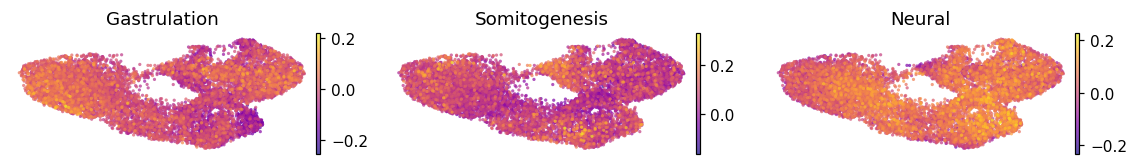

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1,3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=18, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title.split()[0])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout(); plt.show()

### Save the three signature deliverables + colorbars

<string>:15: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:15: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:15: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


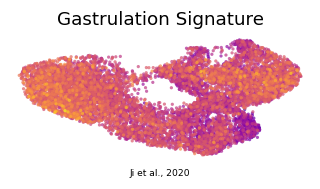

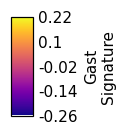

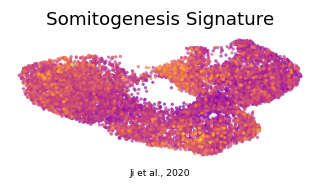

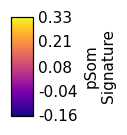

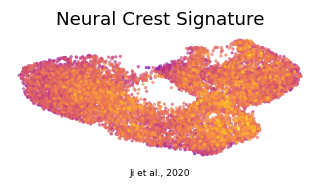

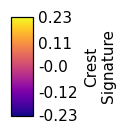

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
for m,title in modules.items():
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=18, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
plt.show()

In [6]:
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (10531, 21042)
